In [1]:
# imports
import simpy
import numpy as np
import sys
import pandas as pd
import os
from IPython.display import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import time


<div dir="rtl">

## מספר זרמי הגעה: 
    
### עד כה ניתחנו מערכות שיש בהם רק זרם הגעה חיצוני יחיד
    
### אבל איך מזינים יותר מזרם הגעה אחד?
    
### למשל בוא נחשוב על המערכת הבאה: 

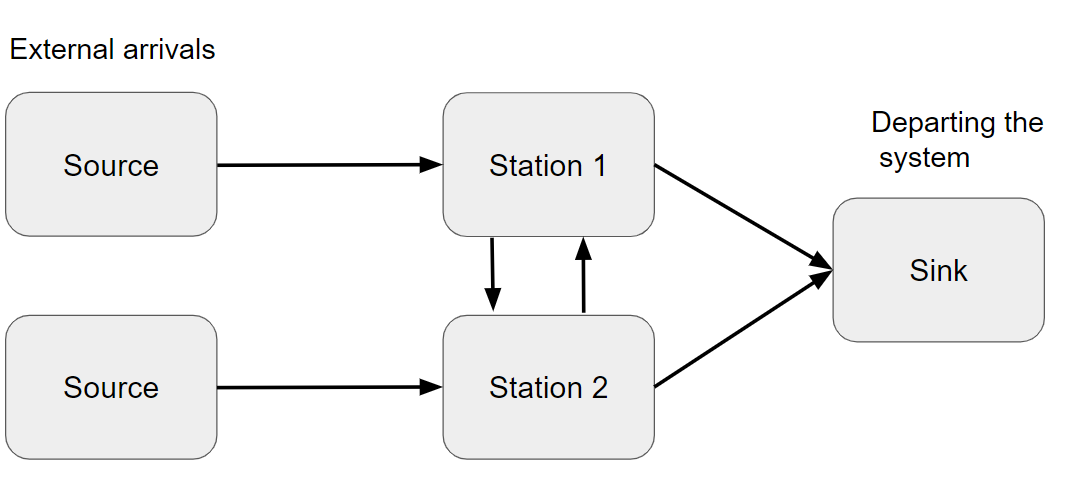

In [2]:
Image('../Images/2_arrival_streams.png', width=620)

<div dir="rtl">

    
### 1. תחילה אני מגדיר את הInput של המערכת
    
### 2. מאתחל מערכת: סביבת עבודה של simpy, נתונים על זמנים בין הגעות וזמני שירות, הסתברויות מעבר, וזמן סימולציה
    
### 3. לאתחל אובייקטים של simpy: שרתים ותהליכי הגעה.
    
### 4. מאתחל מדדים שאני רוצה לעקוב אחריהם למשל: זמני שהייה.
    
### 5.  אתחול מספר סידורי של צרכנים והגדרה של אובייקט צרכן
### זה דבר חדש - אבל עכשיו שיש לנו מספר זרמי הגעה שונים וצרכנים יכולים לחזור לתחנות שהיו כבר אני רוצה לדעת מתי כל צרכן הגיע.
    
### 6. בניית בלוק הגעה: מאפשר לצרכנים להגיע לפי התפלגות זמני הגעה. כולל עדכון של מספר סידורי של צרכן חדש
    
### 7. בניית בלוק שירות: לבקש שירות שצרכן מגיע, להכניס אותו לשירות לפי התפלגות זמני שירות ולשלוח אותו לתחנה הבאה לפי ההסתברויות שקיבלנו בהתחלה
    
### 8.  חישוב המדדים שמעניינים אותנו: למשל זמני שהייה (נמצא בתוך בלוקי הגעה ושירות)
    
### 9. פונקציית run שמריצה את הסימולציה

In [3]:
# part 1
arrival_rates = np.array([1, 1])
service_rates = np.array([2.25, 1.75])
probs = np.array([[0, 0.5], [0.2, 0]])
sim_time = 50000

<div dir="rtl">


### כאשר לקוח מסיים תחנה - נרצה להגריל את ההסתברות שהוא יהיה בתחנה הבאה. 

### נניח הוא בתחנה השניה - כלומר אינדקס 1. 

In [6]:
station = 1
probs[station]

array([0.2, 0. ])

<div dir="rtl">

### בהסתברות 0.2 חוזר לתחנה הראשונה. 

### בהסתברות 0 הוא יישאר לסיבוב נוסף בתחנה הנוכחית

### מה שאומר שבהסברות 0.8 הוא עוזב את המערכת.

### אז צריך להגריל פי ההתפלגות:

### P(to station 1) = 0.2
### P(stays in station 2) = 0
### P(Exit the system) = 0.8

In [7]:

all_probs = np.append(probs[station], 1 - probs[station].sum())
all_probs

array([0.2, 0. , 0.8])

In [98]:
next_station = np.random.choice(3, 1, p=all_probs).item()
next_station

2

In [9]:
## Defining a new class: of customers
# part 5
class Customer:
    def __init__(self, p_id, arrival_time):
        self.id = p_id
        self.arrival_time = arrival_time


class Queue_two_stations_markov_trans:
    
    ###########################################################################
    ###########################################################################
    def __init__(self, arrival_rates, service_rates, probs, sim_time):
        
        #####################################################
        # 2
        self.env = simpy.Environment()  # initializing simpy enviroment
        self.end_time = sim_time  # The time simulation terminate        
        # an event can one of three: (1. arrival, 2. entering service 3. service completion)
        self.service_rates = service_rates  # service rate
        self.arrival_rates = arrival_rates  # inter-arrival rate
        self.probs = probs # transition probs
        #################################################
        #####################################################################################
        # part 3
        ## defining resources
        self.server = []   
        for station in range(2):
            ## Defining the servers
            self.server.append(simpy.Resource(self.env, capacity=1))  # Defining a resource with capacity 1
            
            ## Defining the customers arrivals
            if self.arrival_rates[station] > 0:
                self.env.process(self.customer_arrivals(station))  ## Initializing a process
        
        #####################################################################################
        # part 4
        #####################################################################################
        ## For keeping track on the number of customers in the system
        self.num_cust_durations = []
        self.last_event_time = []  # the time of the last event -
        self.num_cust_sys = []  # keeping track of number of customers in the system
        ####################################      
        
        self.sojourn_times = {}    
        for station in range(2):
            self.sojourn_times[station] = []
            
            ## 
            self.num_cust_durations.append(np.zeros(5000))  ## the time duration of each each state (state= number of cusotmers in the system)
        ##############################################################################################
        # part 5
        self.id_current = 1  # keeping track of cusotmers id
    ########################################################################################
    ########################################################################################
    


     #########################################################
    ################# Arrival block #########################
    #########################################################

    # 6
    
    def customer_arrivals(self, station):

        while True:

            yield self.env.timeout(np.random.exponential(1 / self.arrival_rates[station]))

            curr_id = self.id_current
            arrival_time = self.env.now
            customer = Customer(curr_id, arrival_time)

            self.id_current += 1
            
            self.env.process(self.service(customer, station))

    
    #########################################################
    ################# Service block #########################
    #########################################################
    # part 7
    def service(self, customer, station):

        with self.server[station].request() as req:
            
            # requesting service - meanwhile waiting in line
            yield req
            
            # Startng service
            yield self.env.timeout(np.random.exponential(1 / self.service_rates[station]))           
            #####################################################################
            # part 8
            self.sojourn_times[station].append(self.env.now - customer.arrival_time)
            ######################################################################
        
        ## next station - if 2 means exit the system:
        all_probs = np.append(self.probs[station], 1 - self.probs[station].sum())
        next_station = np.random.choice(3, 1, p=all_probs).item()
        
        
        if next_station < self.probs.shape[0]:
            customer.arrival_time = self.env.now
            self.env.process(self.service(customer, next_station))
        
    
    
    #########################################################################################
    # 9 
    ### Running the simulation
    def run(self):       
        print('Starting simulating two stations system...')
        self.env.run(until=self.end_time)  ## Running the simulaiton until self.end_time
        print('Simulation end')
   ##########################################################################################

In [11]:
queue_two_stations_markov_trans = Queue_two_stations_markov_trans(arrival_rates, service_rates, probs, sim_time)
queue_two_stations_markov_trans.run()

Starting simulating two stations system...
Simulation end


In [14]:
np.array(queue_two_stations_markov_trans.sojourn_times[0]).mean(), np.array(queue_two_stations_markov_trans.sojourn_times[1]).mean()

(np.float64(1.109052649416778), np.float64(11.612922097881839))

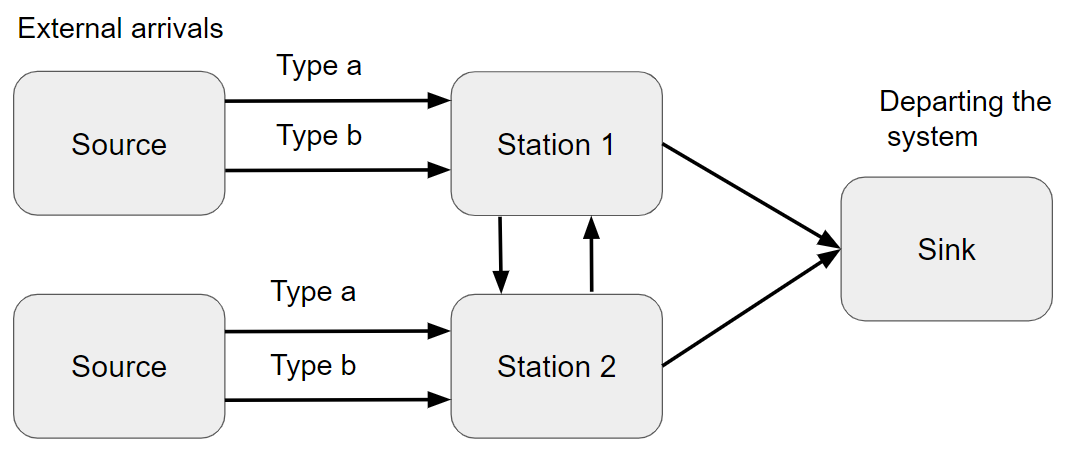

In [13]:
Image('../Images/2_station_different_types.png', width=620)

<div dir="rtl">

    
## מה אם יהיה לנו צרכנים מסוגים שונים?
    
### צריך לדעת מה קצב הגעה לכל תחנה מכל סוג וקצב שירות של כל צרכן מכל סוג ובכל תחנה
    
### אם יש לנו 2 תחנות ו-2 סוגים אז יש סה"כ 4 אפשרויות
    
### בעצם במקרה כזה יש לנו 4 זרמי הגעה. 
    
### כדי שנדע באיזו התפלגות שירות להשתמש צריך בכל רגע נתון לדעת את שם התחנה וסוג הצרכן


<div dir="rtl">

##  נניח כי קצבי הגעה השירות לפי הטבלה הבאה:
    



| Type     | Station |  Arrival Rate  | Service Rate |
| -------- | ------- |         -------|--------------|
| 1        | 1       |      0.5   |        2     |
| 1        | 2       |         1   |        3     |
| 2        | 1       |          1.5   |      2.5     |
| 2        | 2       |         2    |      3.5     |



<div dir="rtl">

### חושב להגיד שאני לא מבדיל בין קצבי הגעה או קצבי שירות. כל התפלגות מעניינת אותי.

### לשם הפשטות אני מניח שהח מעריכי ואז הקצב קובע את כל ההתפלגות.

### בהמשך זה לא יהיה כך. נשתמש בכל מיני התפלגוית שונות ומגוונות.

## סדר פעולות עבודה:
    
### 1. תחילה אני מגדיר את הInput של המערכת
    
### 2. מאתחל מערכת: סביבת עבודה של simpy, נתונים על זמנים בין הגעות וזמני שירות, הסתברויות מעבר, וזמן סימולציה
    
### 3. לאתחל אובייקטים של simpy: שרתים ותהליכי הגעה.
    
### 4. מאתחל מדדים שאני רוצה לעקוב אחריהם למשל: זמני שהייה.
    
### 5.  אתחול מספר סידורי של צרכנים והגדרה של אובייקט צרכן
    
    
### 6. בניית בלוק הגעה: מאפשר לצרכנים להגיע לפי התפלגות זמני הגעה. כולל עדכון של מספר סידורי של צרכן חדש
    
### 7. בניית בלוק שירות: לבקש שירות שצרכן מגיע, להכניס אותו לשירות לפי התפלגות זמני שירות ולשלוח אותו לתחנה הבאה לפי ההסתברויות שקיבלנו בהתחלה
    
### 8.  חישוב המדדים שמעניינים אותנו: למשל זמני שהייה (נמצא בתוך בלוקי הגעה ושירות)
    
### 9. פונקציית run שמריצה את הסימולציה

In [15]:
# 1
arrival_rates = {(1, 'a') : 1,(2, 'a') : 1.25,(1, 'b') : 1.75,(2, 'b') : 2}
service_rates = {(1, 'a') : 4.9,(2, 'a') : 4.25,(1, 'b') : 3.1,(2, 'b') : 3.9}
probs = np.array([[0, 0.5], [0.2, 0]]) 
sim_time = 50000

In [17]:
## Defining a new class: of customers
# part of 5
class Customer:
    def __init__(self, p_id, arrival_time, type_cust):
        self.id = p_id
        self.arrival_time = arrival_time
        self.type = type_cust


class Queue_two_stations_different_types:

    def __init__(self, arrival_rates, service_rates, probs, sim_time):
        
        ################################################################
        # part 2
        self.env = simpy.Environment()  # initializing simpy enviroment
        self.end_time = sim_time  # The time simulation terminate
        # an event can one of three: (1. arrival, 2. entering service 3. service completion)
        
        self.service_rates = service_rates  # service rate
        self.arrival_rates = arrival_rates  # inter-arrival rate
        self.probs = probs # transition probs
        
        #################################################################
        
        # part 3
        self.server = {}
        for station in range(1,3):
            ## Servers
            
            self.server[station] = simpy.Resource(self.env, capacity=1)  # Defining a resource with capacity 1
            
            ## Arrivals
            for type_cust in ['a', 'b']:
                if self.arrival_rates[(station, type_cust)] > 0:
                    self.env.process(self.customer_arrivals(station, type_cust))  ## Initializing a process
        
        ####################################################################
        # part 4 
        self.num_cust_durations = {}
        # the time of the last event -
        self.num_cust_sys = {}  # keeping track of number of customers in the system
        self.waiting_times = {}
        self.last_event_time = {}
        self.num_cust_durations = {}
        
        for station in range(1,3):
                    
            self.num_cust_durations[station] = np.zeros(5000)  ## the time duration of each each state (state= number of cusotmers in the system)
            self.num_cust_sys[station] = 0
            self.waiting_times[station] = []
            self.last_event_time[station] = 0     
        
        ########################################################
        # part 5
        self.id_current = 1  # keeping track of cusotmers id
        ########################################################
    
    #########################################################
    ################# Arrival block #########################
    #########################################################
    # part 6
    def customer_arrivals(self, station, customer_type):

        while True:

            yield self.env.timeout(np.random.exponential(1 / self.arrival_rates[(station, customer_type)]))

            curr_id = self.id_current
            arrival_time = self.env.now
            customer = Customer(curr_id, arrival_time, customer_type)

            self.id_current += 1      
            self.env.process(self.service(customer, station))
    
    
    
    #########################################################
    ################# Service block #########################
    #########################################################
    # part 7
    def service(self, customer, station):   
        
        ################################
        ### part of 8    ###############
        ################################
        
        tot_time = self.env.now - self.last_event_time[station]
        self.num_cust_durations[station][self.num_cust_sys[station]] += tot_time
        self.num_cust_sys[station] += 1
        self.last_event_time[station] = self.env.now
        ###############################
    
        #### requesting service
        with self.server[station].request() as req:

            yield req     
            ###### entering service ################################
            
            yield self.env.timeout(np.random.exponential(1 / self.service_rates[(station, customer.type)]))

            
            ################################
            ### part of 8    ###############
            ################################
            
            tot_time = self.env.now - self.last_event_time[station]  # keeping track of the last event
            self.num_cust_durations[station][self.num_cust_sys[station]] += tot_time  
            # Since the number of customers in the system changes
            # we compute how much time the system had this number of customers
            self.num_cust_sys[station] -= 1  # updating number of cusotmers in the system
            self.last_event_time[station] = self.env.now
            
            
            self.waiting_times[station].append(self.env.now - customer.arrival_time)
            ################################

        ## next station - if 2 means exit the system:
        all_probs = np.append(self.probs[station-1], 1 - self.probs[station-1].sum())

        next_station = np.random.choice(3, 1, p=all_probs).item() + 1
        if next_station < all_probs.shape[0]-1:
            customer.arrival_time = self.env.now
            self.env.process(self.service(customer, next_station))

            
    
    ########################################################################
    # 9
    def run(self):
        
        print('Starting simulating two stations system...')
        self.env.run(until=self.end_time)  ## Running the simulaiton until self.end_time
        print('Simulation end')
    #########################################################################

In [18]:
queue_two_stations_different_types = Queue_two_stations_different_types(arrival_rates, service_rates, probs, sim_time)
queue_two_stations_different_types.run()

Starting simulating two stations system...
Simulation end


In [19]:
queue_two_stations_different_types.num_cust_durations[1][:6]

array([2507.71457535, 2327.93768111, 2260.90686022, 2152.75742311,
       2083.03269341, 1960.29208137])

In [20]:
probs_station_1 = (queue_two_stations_different_types.num_cust_durations[1]/queue_two_stations_different_types.num_cust_durations[1].sum())
probs_station_2 = (queue_two_stations_different_types.num_cust_durations[2]/queue_two_stations_different_types.num_cust_durations[2].sum())

In [21]:
probs_station_1[:6]

array([0.05015491, 0.04655933, 0.04521869, 0.04305568, 0.04166117,
       0.03920632])

<div dir="rtl">

## התפלגות מספר צרכנים בכל תור: 

In [22]:
probs_station_1[10:].sum()

np.float64(0.5982124347989899)

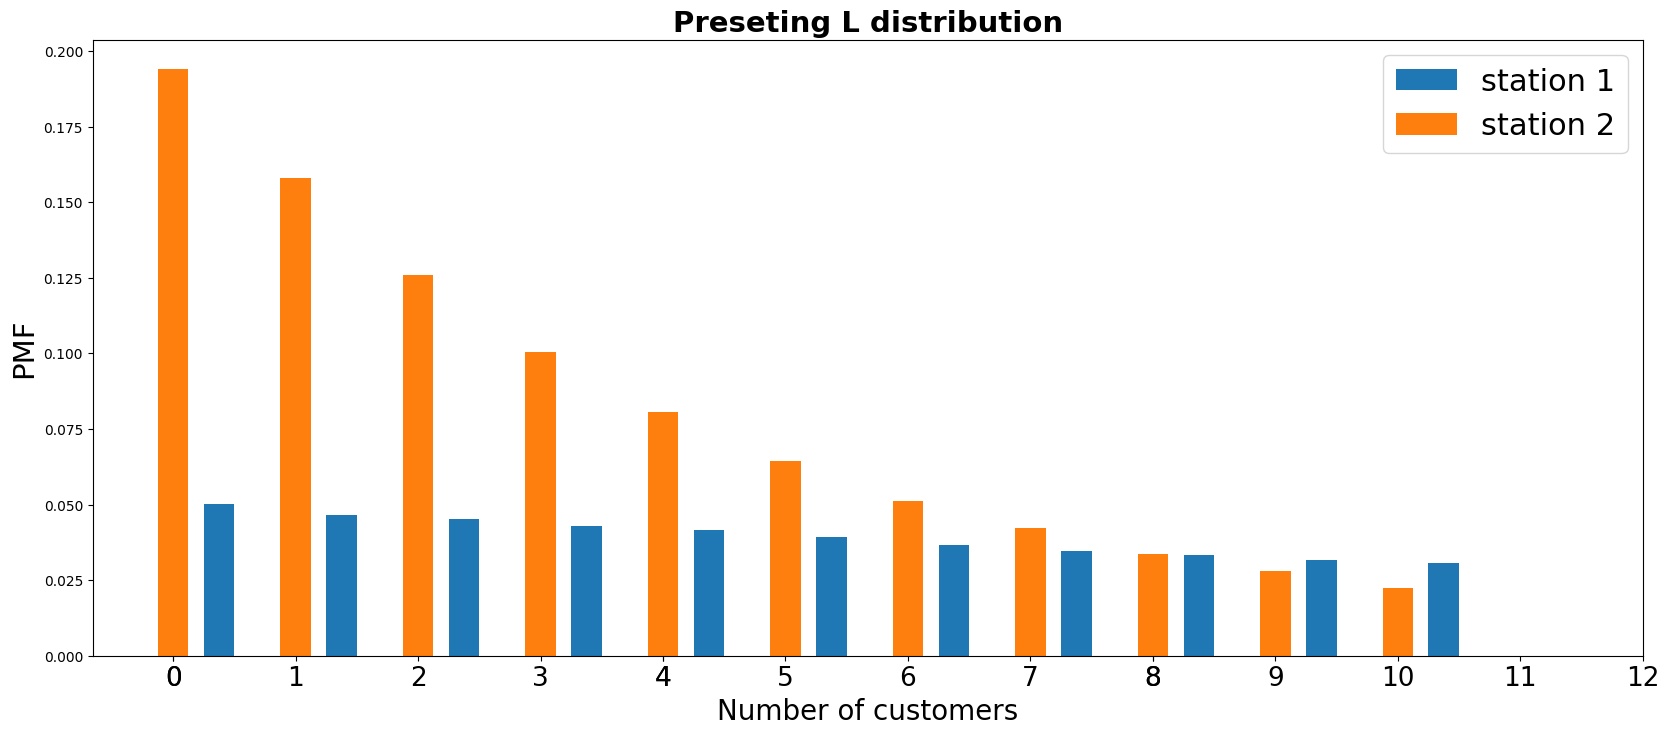

In [23]:
## Plotting the graph

fig, (ax1) = plt.subplots(1, 1, figsize=(20, 8))
width = 0.25
max_probs = 11
rects1 = ax1.bar(1.5*width+np.arange(max_probs), probs_station_1[:11], width, label='station 1')
rects2 = ax1.bar(np.arange(max_probs) , probs_station_2[:11], width, label='station 2')
plt.rcParams['font.size'] = '20'

# # Add some text for labels, title and custom x-axis tick labels, etc.
ax1.set_ylabel('PMF', fontsize=21)
ax1.set_xlabel('Number of customers', fontsize=20)
ax1.set_title( 'Preseting L distribution' , fontsize=21, fontweight="bold")
ax1.set_xticks(np.linspace(0,12,16).astype(int))
ax1.set_xticklabels(np.linspace(0,12,16).astype(int), fontsize=19)
ax1.legend(fontsize=22)
plt.show()

<div dir="rtl">

### חישובי תוחלות של מספר צרכנים במערכת: 

## $$ E[X] = \sum_{i \geq 0}P_i x_i $$

In [106]:
np.arange(5).shape[0]

5

In [24]:
(np.arange(probs_station_1.shape[0])*probs_station_1).sum()

np.float64(20.418870493029765)

In [25]:
(np.arange(probs_station_2.shape[0])*probs_station_2).sum()

np.float64(4.225885236865576)

<div dir="rtl">

## בואו נשווה בין סוגי צרכנים בכל אחת מהתחנות

### נרצה לחשב התפלגות זמני המתנה של כל צרכן בכל תחנה
    
#### כרגע הקוד שלנו לא עושה את המעקב הזה, לכן נצטרך להכניס שינויים:


In [27]:
# 1
arrival_rates = {(1, 'a') : 1,(2, 'a') : 1.25,(1, 'b') : 1.75,(2, 'b') : 2}
service_rates = {(1, 'a') : 4.9,(2, 'a') : 4.25,(1, 'b') : 3.1,(2, 'b') : 3.9}
probs = np.array([[0, 0.5], [0.2, 0]]) 
sim_time = 50000

In [29]:
## Defining a new class: of customers
# part of 5
class Customer:
    def __init__(self, p_id, arrival_time, type_cust):
        self.id = p_id
        self.arrival_time = arrival_time
        self.type = type_cust


class Queue_two_stations_different_types:

    def __init__(self, arrival_rates, service_rates, probs, sim_time):
        # 2
        ##############################################
        self.env = simpy.Environment()  # initializing simpy enviroment
        self.end_time = sim_time  # The time simulation terminate
        
        # an event can one of three: (1. arrival, 2. entering service 3. service completion)
        self.service_rates = service_rates  # service rate
        self.arrival_rates = arrival_rates  # inter-arrival rate
        self.probs = probs # transition probs
        ##############################################
        

        
        ######################################
        # 3
        self.server = {}
        for station in range(1,3):
            
            self.server[station] = simpy.Resource(self.env, capacity=1)  # Defining a resource with capacity 1
            
            for type_cust in ['a', 'b']:
                if self.arrival_rates[(station, type_cust)] > 0:
                    self.env.process(self.customer_arrivals(station, type_cust))  ## Initializing a process
        ################################################
        
        
        ###########################################
        # 4
        self.num_cust_durations = {}
        self.num_cust_sys = {}  # keeping track of number of customers in the system
        self.waiting_times = {}
        self.last_event_time = {}
        self.num_cust_durations = {}
        self.queueing_time = {}
        
        for station in range(1,3):
            
            self.num_cust_durations[station] = np.zeros(5000)  ## the time duration of each each state (state= number of cusotmers in the system)
            self.num_cust_sys[station] = 0
            self.waiting_times[station] = []
            self.last_event_time[station] = 0 
            ### This is new
            for type_ in ['a', 'b']:
                self.queueing_time[(station, type_)] = []            
    
        # 5 
        self.id_current = 1  # keeping track of cusotmers id
    
    #########################################################
    ################# Arrival block #########################
    #########################################################
    
    ###################################
    # 6
    def customer_arrivals(self, station, customer_type):

        while True:

            yield self.env.timeout(np.random.exponential(1 / self.arrival_rates[(station, customer_type)]))

            curr_id = self.id_current
            arrival_time = self.env.now
            customer = Customer(curr_id, arrival_time, customer_type)

            self.id_current += 1      
            self.env.process(self.service(customer, station))
    
    

    #########################################################
    ################# Service block #########################
    #########################################################
    # 7
    def service(self, customer, station):
        
        ################################
        ### part of 8    ###############
        ################################
        
        arrival_time =  self.env.now
        tot_time = self.env.now - self.last_event_time[station]
        self.num_cust_durations[station][self.num_cust_sys[station]] += tot_time
        self.num_cust_sys[station] += 1
        self.last_event_time[station] = self.env.now
        
        ##########################
        with self.server[station].request() as req:

            
            yield req
            
            ################################
            ### part of 8    ###############
            ################################
            self.queueing_time[(station, customer.type)].append(self.env.now-arrival_time) ## This is new
            #######################################
            yield self.env.timeout(np.random.exponential(1 / self.service_rates[(station, customer.type)]))
            
            
            ################################
            ### part of 8    ###############
            ################################
            
            tot_time = self.env.now - self.last_event_time[station]  # keeping track of the last event
            self.num_cust_durations[station][self.num_cust_sys[station]] += tot_time  # Since the number of customers in the system changes
            # we compute how much time the system had this number of customers
            self.num_cust_sys[station] -= 1  # updating number of cusotmers in the system
            self.last_event_time[station] = self.env.now
            self.waiting_times[station].append(self.env.now - customer.arrival_time)
            ############################################
            
        ## next station - if 2 means exit the system:
        all_probs = np.append(self.probs[station-1], 1 - self.probs[station-1].sum())
        next_station = np.random.choice(3, 1, p=all_probs).item() + 1
        if next_station < all_probs.shape[0]-1:
            customer.arrival_time = self.env.now
            self.env.process(self.service(customer, next_station))

    # part 9
    def run(self):
        
        print('Starting simulating two stations system...')
        self.env.run(until=self.end_time)  ## Running the simulaiton until self.end_time
        print('Simulation end')



In [30]:
queue_two_stations_different_types = Queue_two_stations_different_types(arrival_rates, service_rates, probs, sim_time)
queue_two_stations_different_types.run()

Starting simulating two stations system...
Simulation end


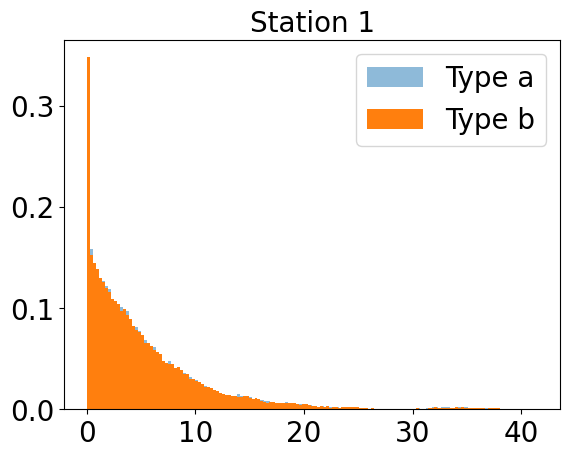

In [31]:
plt.figure()
plt.hist(queue_two_stations_different_types.queueing_time[(1,'a')], density = True, bins = 150, alpha= 0.5, label = 'Type a')
plt.hist(queue_two_stations_different_types.queueing_time[(1,'b')], density = True, bins = 150, label = 'Type b')
plt.legend()
plt.title('Station 1' , fontsize = 20)
plt.show()

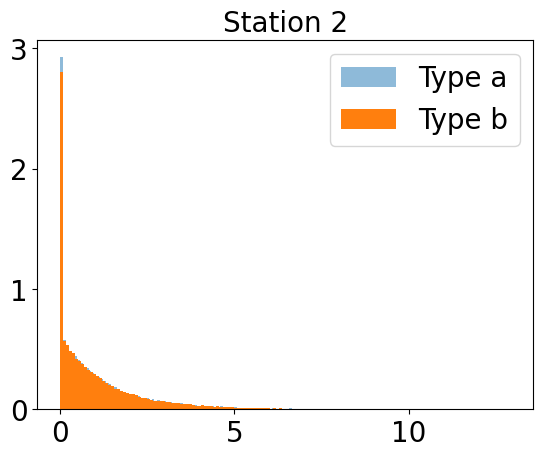

In [32]:
plt.figure()
plt.hist(queue_two_stations_different_types.queueing_time[(2,'a')], density = True, bins = 150, alpha= 0.5, label = 'Type a')
plt.hist(queue_two_stations_different_types.queueing_time[(2,'b')], density = True, bins = 150, label = 'Type b')
plt.legend()
plt.title('Station 2' , fontsize = 20)
plt.show()

<div dir="rtl">

### בשתי התחנות זמני המתנה נראים אותו דבר
    
### למרות שיש שני סוגים עם זמני שירות שונים
    
### למה????
    
### זה בגלל שזהות הצרכן לא משפיעה על זמן ההמתנה בתור. רק כאשר הוא נכנס לשירות זהותו משפיעה אבל זה לא נכלל בחישוב של זמן המתנה. אם זה היה זמן שהייה אז היה הבדל. 